<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Risk/VaR_CVaR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
VaR (Value at Risk): The potential loss in value of an asset/portfolio given:
                    1) A specific time period
                    2) A confidence level

cVaR (Conditional VaR): Also called as ES(Expected shortfall)
                      The average of losses beyond the VaR for a given confidence level.
'''

'''
This notebook contains:

1) VaR using 3 methods
1.a) Historical
1.b) Parametric
1.c) Simulation(Monte carlo)

2) cVaR using 3 methods
2.a) Historical
2.b) Parametric
2.c) Simulation
'''

In [31]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import datetime as dt
from scipy.stats import norm

# Download and close prices/returns data for a time period
years = 15
start_date = dt.datetime.today() - dt.timedelta(days=365*years)
end_date = dt.datetime.today()
#start_date = '2008-04-28'
#end_date = '2023-04-25'

tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']
adj_close = pd.DataFrame()

for ticker in tickers:
  # Use multi_level_index=False to prevent MultiIndex columns and retrieve the adjusted 'Close'
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
  adj_close[ticker] = data['Close']

# Log Returns
log_ret = np.log(adj_close / adj_close.shift(1))
log_ret.dropna(inplace=True)

# Portfolio
# Weighing equally weighted
weights = np.array([1/len(tickers)]*len(tickers))

# Portfolio historical returns
p_ret = (log_ret * weights).sum(axis=1)


/tmp/ipykernel_843/2729481070.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_843/2729481070.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_843/2729481070.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_843/2729481070.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_in

In [ ]:
'''VaR Historical calculations'''
# Time period(days) and confidence level
n = 5
confidence_level = 0.95
Portfolio_value = 1000000

p_ndays_ret = p_ret.rolling(window=n).sum()
p_ndays_ret.dropna(inplace=True)
print(p_ndays_ret)

VaR = -np.percentile(p_ndays_ret, (1-confidence_level)*100)*Portfolio_value
print(VaR)

# visualisations

In [99]:
'''VaR Parametric calculations
The parametric method calculates VaR by assuming returns follow a normal distribution.
typically(normal but can be excess kurtosis and skewness)
and using mean and std dev of historical returns to estimate the potential losses at a given confidence level.
95%-single sided z score = 1.65
'''
n = 5
Portfolio_value = 1000000

p_ndays_ret = p_ret.rolling(window=n).sum()
p_ndays_ret.dropna(inplace=True)

# Need mean and std. dev. of portfolio for parametric
cov_matrix = log_ret.cov()*252
p_std_dev = np.sqrt(weights.T @ cov_matrix @ weights)


confidence_level = [0.90, 0.95, 0.99]
VaRs = []

for c in confidence_level:
  VaR = -Portfolio_value *(p_ret.mean() * n + p_std_dev * norm.ppf(1-c) * np.sqrt(n/252))
  VaRs.append(VaR)

print(f'{'Confidence level':<20} {'Value at Risk':<20}')
print('-'*40)
for c in range(len(confidence_level)):
  print(f'{confidence_level[c]:.2f}{'':<15} ${VaRs[c]:.2f}')


Confidence level     Value at Risk       
----------------------------------------
0.90                $22511.17
0.95                $29338.04
0.99                $42144.10


VaR: $69819.20
Confidence level    VaR       
----------------------------------------
0.90            $35,023.12
0.95            $46,850.86
0.99            $69,819.20


VaR:  $69,819.20
CVaR: $81,345.68




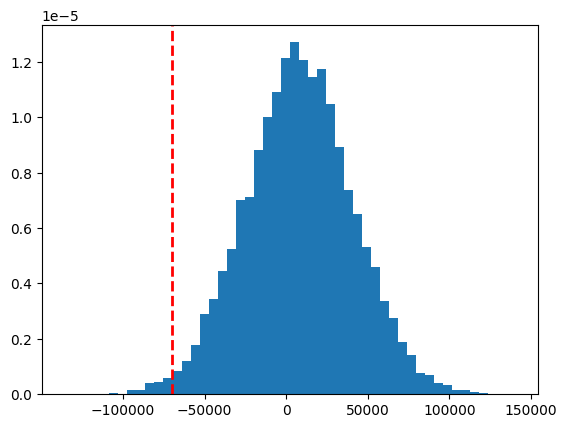

In [104]:
'''VaR Monte Carlo simulations
Simulate future price paths.
Based on asset's statistical properties(mu, sigma)
1000s of simulations
Calculate potential losses for each simulation
VaR is derived from the distribution of simulated losses.

DONEfunction to calculate the expected return of the portfolio
DONEfunction to calculate the std deviation
randon number generation for the simulations
simulate the returns for stocks in the portfolio
'''

Portfolio_value = 1000000
days = 20
confidence_level = 0.99

def p_expected_returns(weights, log_ret):
    p_exp_ret = np.sum(log_ret.mean() * weights)
    return p_exp_ret


cov_matrix = log_ret.cov()
def p_std_dev(weights, cov_matrix):
    std_dev = np.sqrt(weights.T @ cov_matrix @ weights)
    return std_dev

rng = np.random.default_rng(42)
def rand_z():
    rnd = rng.normal(0,1)
    return rnd


def simulate(Portfolio_value, exp_ret, std_dev, days, z):
    sim = Portfolio_value * exp_ret * days + Portfolio_value * std_dev * z * np.sqrt(days)
    return sim

exp_ret = p_expected_returns(weights, log_ret)
std_dev = p_std_dev(weights, cov_matrix)

n_sims = 10000
sims = []

for i in range(n_sims):
    z = rand_z()
    sim = simulate(Portfolio_value, exp_ret, std_dev, days, z)
    sims.append(sim)


VaR = -np.percentile(sims, 100*(1-confidence_level))
print(f'VaR: ${VaR:.2f}')

confidence_levels = [.90, .95, .99]
VaRs = []
for c in confidence_levels:
  var = -np.percentile(sims, 100*(1-c))
  VaRs.append(var)

print(f"{'Confidence level':<20}{'VaR':<10}")
print("-"*40)
for c in range(len(confidence_levels)):
  print(f'{confidence_levels[c]:.2f} {'':<10} ${VaRs[c]:,.2f}')
print('\n')

# Visualizations
plt.hist(sims, bins=50, density=True)
plt.axvline(-VaR, color='r', linestyle='dashed', linewidth=2, label=f'VaR at {confidence_level:.0%} confidence level')

# cVaR
sims = np.array(sims)
cVaR = -np.mean(sims[sims<=-VaR])
print(f'VaR:  ${VaR:,.2f}')
print(f'CVaR: ${cVaR:,.2f}')
print('\n')

Remember:
Log returns are not additive across assets
